# House price prediction - the manual version

A hand-written data-science pass over `datasets/house prices.csv` (King County house sales,
4 600 rows, 18 columns), written to be read top to bottom.

**How this notebook is meant to be read**

- Every block is run and its output saved, **including the failures**. One cell raises a real
  exception on purpose, and one model produces impossible predictions on purpose. Both are marked
  FAILURE, KEPT ON PURPOSE, and both are part of the story.
- Protocol: split 70 / 15 / 15 (train / validation / test). The **validation** set is used for
  every comparison and tuning decision; the **test** set is touched exactly once at the end.
- Nothing here is imported by the StudyGraph app - this is the independent comparison experiment.

## 0. Setup

Pandas 3, scikit-learn 1.9, numpy 2. Nothing exotic: every number below is produced by running
the cell above it.

In [2]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge, RidgeCV
from sklearn.metrics import accuracy_score, confusion_matrix, mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True

RANDOM_STATE = 42
TARGET = "price"
candidates = [Path("datasets/house prices.csv"), Path("regression/datasets/house prices.csv")]
DATA_PATH = next(p for p in candidates if p.exists())

results = []

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def record(name, y_true, y_pred, notes=""):
    row = {
        "model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": rmse(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "notes": notes,
    }
    results.append(row)
    return row

print("data    :", DATA_PATH.resolve())
print("pandas  :", pd.__version__)
print("numpy   :", np.__version__)
print("sklearn :", sklearn.__version__)

data    : C:\Users\novij\Desktop\Pba Softwareudvikling\2. Semester\LLMs for udviklere\project\LLM-group-a\exam_project\regression\datasets\house prices.csv
pandas  : 3.1.1
numpy   : 2.5.4
sklearn : 1.9.1


## 1. Load and look at the data

In [3]:
raw = pd.read_csv(DATA_PATH)
df = raw.copy()
print("rows, columns:", df.shape)
print("memory:", round(df.memory_usage(deep=True).sum() / 1e6, 2), "MB")
df.head(3)

rows, columns: (4600, 18)
memory: 0.91 MB


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.5,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.5,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.0,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA


In [4]:
kind = pd.DataFrame({
    "pandas dtype": df.dtypes.astype(str),
    "unique values": df.nunique(),
    "first value": [df[c].iloc[0] for c in df.columns],
})
kind

,pandas dtype,unique values,first value
date,str,70,2014-05-02 00:00:00
price,float64,1741,313000.0
bedrooms,float64,10,3.0
bathrooms,float64,26,1.5
sqft_living,int64,566,1340
sqft_lot,int64,3113,7912
floors,float64,6,1.5
waterfront,int64,2,0
view,int64,5,0
condition,int64,5,3


The dtypes already tell the story: `date` is a **string**, `price` and a few counts are
floats, and four columns are free text (`street`, `city`, `statezip`, `country`).
`bedrooms`, `bathrooms` and `floors` should really be integers - they only became floats
somewhere upstream, which is harmless for modelling but worth knowing.

### Correct the datatypes

Six columns hold whole numbers but are stored as floats. `bathrooms` (2.25) and `floors` (1.5)
genuinely are fractional, so they stay as they are. The cell checks before it casts, so it can
never silently truncate a real value.

In [5]:
integral_cols = ["bedrooms", "view", "condition", "waterfront", "yr_built", "yr_renovated"]
safe = [c for c in integral_cols if bool(np.allclose(df[c], df[c].round()))]
df[safe] = df[safe].astype(int)
print("cast to int :", safe)
print("left as is  :", ["bathrooms", "floors"])
df[safe].dtypes.to_frame("dtype")

cast to int : ['bedrooms', 'view', 'condition', 'waterfront', 'yr_built', 'yr_renovated']
left as is  : ['bathrooms', 'floors']


,dtype
bedrooms,int64
view,int64
condition,int64
waterfront,int64
yr_built,int64
yr_renovated,int64


## 2. Data quality: invalid rows, duplicates, missing values

In [6]:
checks = {
    "price <= 0": int((df["price"] <= 0).sum()),
    "bedrooms == 0": int((df["bedrooms"] == 0).sum()),
    "bathrooms == 0": int((df["bathrooms"] == 0).sum()),
    "sqft_living <= 0": int((df["sqft_living"] <= 0).sum()),
    "sqft_lot <= 0": int((df["sqft_lot"] <= 0).sum()),
    "yr_built < 1900": int((df["yr_built"] < 1900).sum()),
    "exact duplicate rows": int(df.duplicated().sum()),
}
pd.Series(checks, name="rows").to_frame()

,rows
price <= 0,49
bedrooms == 0,2
bathrooms == 0,2
sqft_living <= 0,0
sqft_lot <= 0,0
yr_built < 1900,0
exact duplicate rows,0


In [7]:
missing = df.isna().sum()
print("missing cells in total:", int(missing.sum()))
if bool((missing > 0).any()):
    print(missing[missing > 0])
else:
    print("no missing values anywhere, column by column")

missing cells in total: 0
no missing values anywhere, column by column


In [8]:
print("yr_renovated == 0 (never renovated):", int((df["yr_renovated"] == 0).sum()), "of", len(df))
print("smallest non-zero yr_renovated:", int(df.loc[df["yr_renovated"] > 0, "yr_renovated"].min()))
print("renovated before built (impossible):", int(((df["yr_renovated"] > 0) & (df["yr_renovated"] < df["yr_built"])).sum()))

yr_renovated == 0 (never renovated): 2735 of 4600
smallest non-zero yr_renovated: 1912
renovated before built (impossible): 195


In [9]:
# Drop rows that cannot be a real sale, then de-duplicate. Report exactly what left.
before = len(df)
df = df[(df["price"] > 0) & (df["bedrooms"] > 0) & (df["bathrooms"] > 0) & (df["sqft_living"] > 0) & (df["sqft_lot"] > 0)].copy()
df = df.drop_duplicates()
print(f"kept {len(df)} of {before} rows ({before - len(df)} removed: impossible values or duplicates)")

kept 4549 of 4600 rows (51 removed: impossible values or duplicates)


## 3. Distributions

Skew matters here: `price` and `sqft_lot` are famously heavy-tailed, which is exactly why a
log target is worth testing later.

In [10]:
num_cols = df.select_dtypes("number").columns.drop(TARGET)
summary = pd.DataFrame({
    "mean": df[num_cols].mean(),
    "std": df[num_cols].std(),
    "min": df[num_cols].min(),
    "median": df[num_cols].median(),
    "max": df[num_cols].max(),
    "skew": df[num_cols].skew(),
})
summary.sort_values("skew", key=lambda s: s.abs(), ascending=False).round(2)

,mean,std,min,median,max,skew
waterfront,0.01,0.08,0.00,0.00,1.0,12.20
sqft_lot,14834.60,35971.14,638.00,7680.00,1074218.0,11.33
view,0.23,0.77,0.00,0.00,4.0,3.38
sqft_living,2131.58,955.23,370.00,1970.00,13540.0,1.72
sqft_basement,310.29,462.04,0.00,0.00,4820.0,1.65
sqft_above,1821.29,853.29,370.00,1590.00,9410.0,1.45
condition,3.45,0.68,1.00,3.00,5.0,0.96
bathrooms,2.16,0.78,0.75,2.25,8.0,0.60
floors,1.51,0.54,1.00,1.50,3.5,0.55
yr_built,1970.79,29.76,1900.00,1976.00,2014.0,-0.51


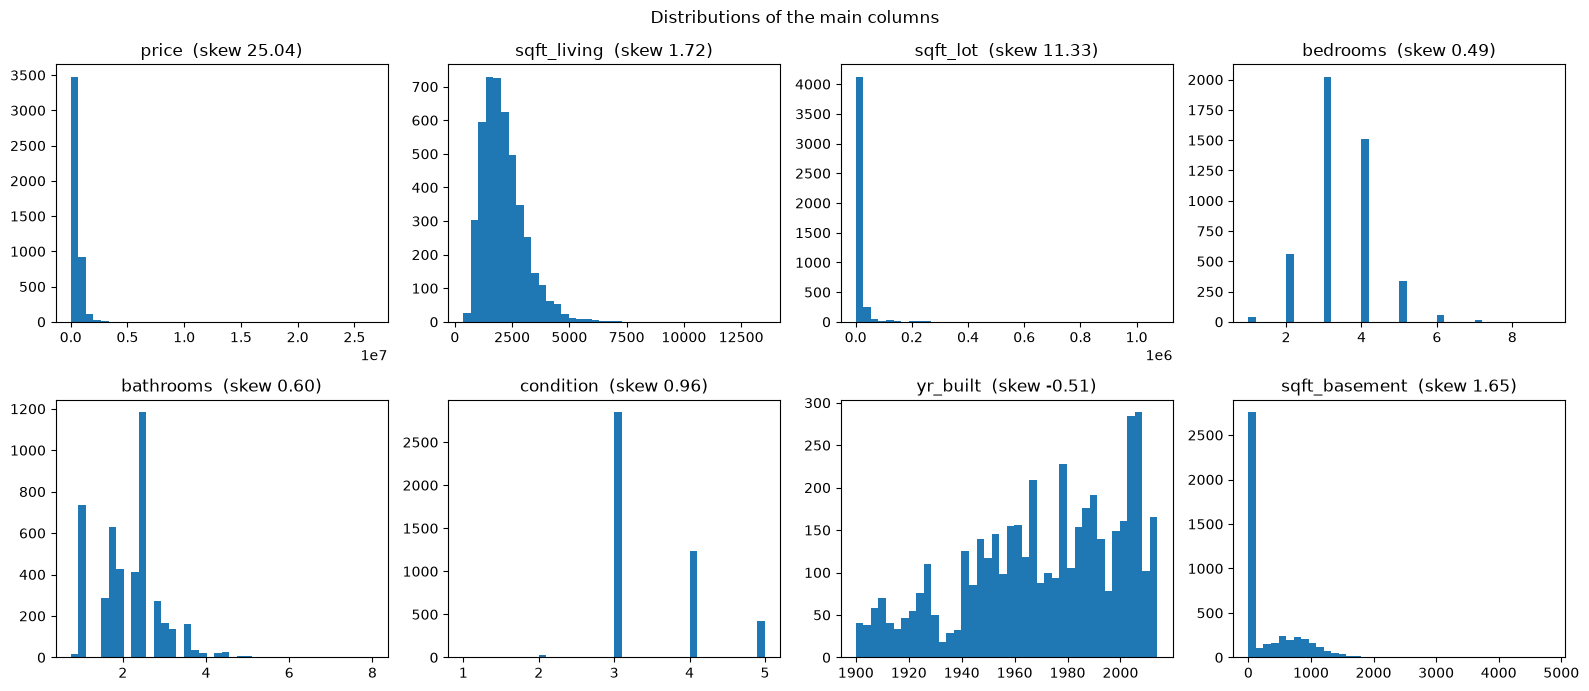

In [11]:
cols = ["price", "sqft_living", "sqft_lot", "bedrooms", "bathrooms", "condition", "yr_built", "sqft_basement"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), cols):
    ax.hist(df[col], bins=40)
    ax.set_title(f"{col}  (skew {df[col].skew():.2f})")
    ax.grid(False)
fig.suptitle("Distributions of the main columns")
fig.tight_layout()

price skew        : 25.041
log1p(price) skew : 0.331


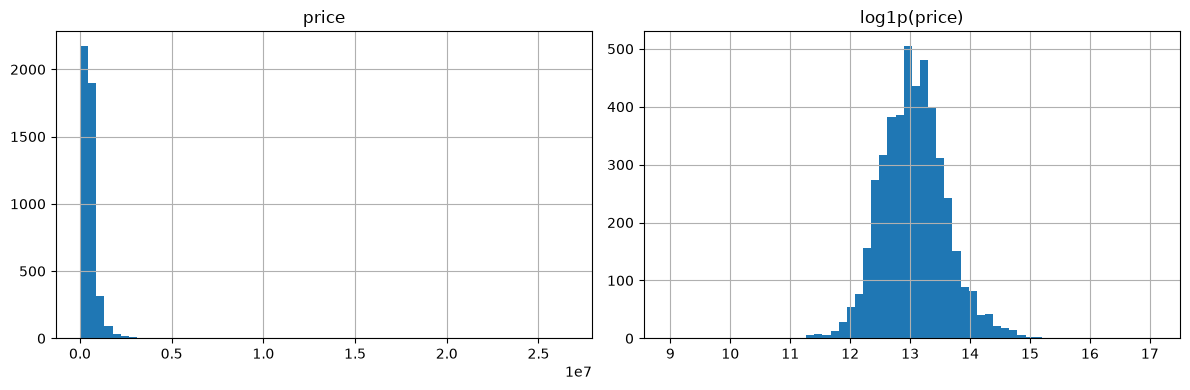

In [12]:
print("price skew        :", round(float(df["price"].skew()), 3))
print("log1p(price) skew :", round(float(np.log1p(df["price"]).skew()), 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["price"], bins=60)
axes[0].set_title("price")
axes[1].hist(np.log1p(df["price"]), bins=60)
axes[1].set_title("log1p(price)")
fig.tight_layout()

## 4. Correlations

In [13]:
corr = df.corr(numeric_only=True)[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False)
corr.round(3).to_frame("correlation with price")

,correlation with price
sqft_living,0.445
sqft_above,0.380
bathrooms,0.343
view,0.242
sqft_basement,0.218
bedrooms,0.213
floors,0.152
waterfront,0.150
sqft_lot,0.051
condition,0.039


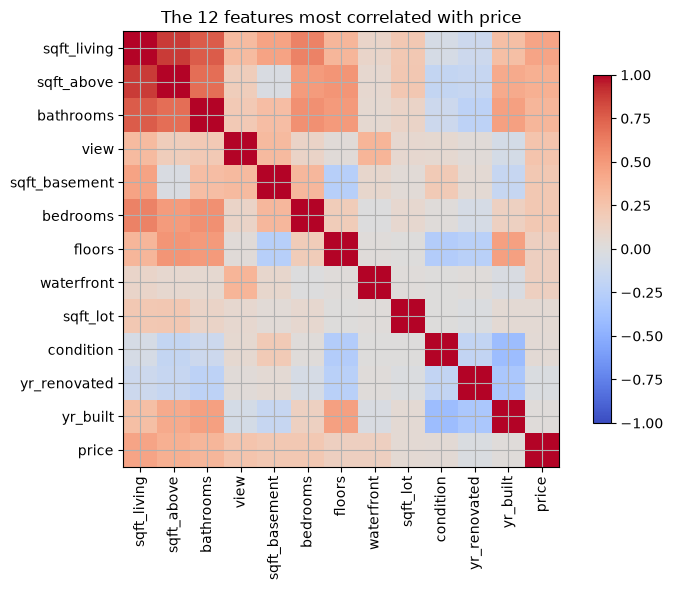

In [14]:
top = corr.abs().sort_values(ascending=False).head(12).index.tolist()
matrix = df[top + [TARGET]].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(matrix.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(matrix)), matrix.columns, rotation=90)
ax.set_yticks(range(len(matrix)), matrix.columns)
ax.set_title("The 12 features most correlated with price")
fig.colorbar(image, ax=ax, shrink=0.8)
fig.tight_layout()

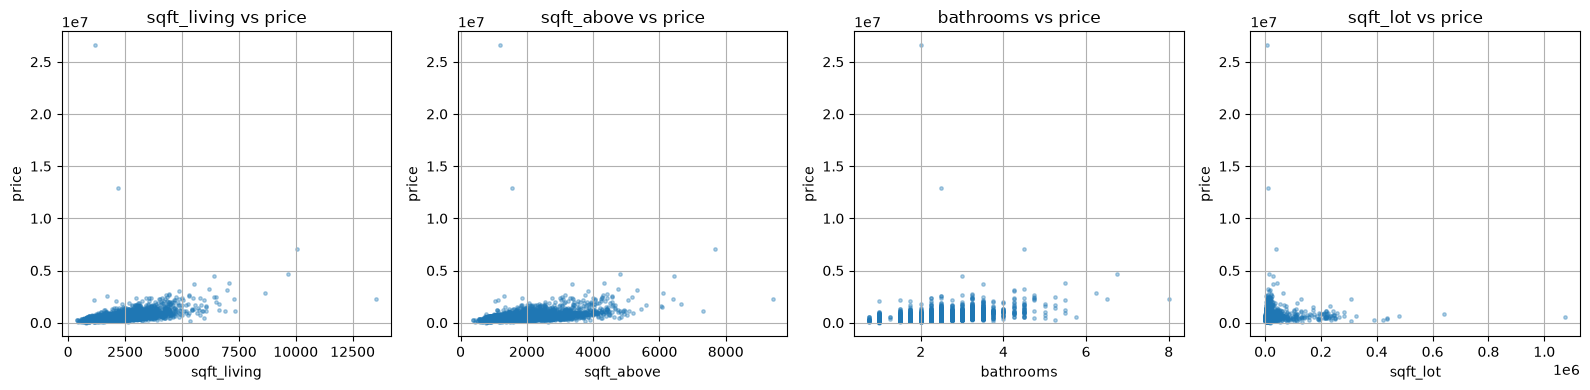

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ["sqft_living", "sqft_above", "bathrooms", "sqft_lot"]):
    ax.scatter(df[col], df[TARGET], s=6, alpha=0.35)
    ax.set_xlabel(col)
    ax.set_ylabel("price")
    ax.set_title(f"{col} vs price")
fig.tight_layout()

## 5. Outliers

Outliers are not automatically errors. A 7.06 M house at 10 040 sqft is a real luxury sale, and
deleting it would teach the model that big houses are cheap. So the rule is: measure first, then
remove only what is **impossible**, never what is merely unusual.

Two other prices in this file *are* impossible, and one of them silently ruins R2 and RMSE for every
model in the notebook. The cells below find them by price per square foot rather than by raw price,
because a high price is normal for a big house but a high price per square foot is not.

In [16]:
def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)).sum())

outliers = pd.DataFrame({"outliers (1.5 IQR)": {c: iqr_outliers(df[c]) for c in num_cols}})
outliers["share of rows"] = (outliers["outliers (1.5 IQR)"] / len(df) * 100).round(1)
outliers.sort_values("outliers (1.5 IQR)", ascending=False)

,outliers (1.5 IQR),share of rows
sqft_lot,539,11.8
view,447,9.8
bathrooms,128,2.8
sqft_living,127,2.8
bedrooms,113,2.5
sqft_above,110,2.4
sqft_basement,83,1.8
waterfront,30,0.7
condition,6,0.1
floors,0,0.0


In [17]:
# Measured experiment: does IQR-trimming sqft_lot help a plain linear regression?
def quick_fit(frame, features):
    train_part, test_part = train_test_split(frame, test_size=0.2, random_state=RANDOM_STATE)
    model = LinearRegression().fit(train_part[features], train_part[TARGET])
    pred = model.predict(test_part[features])
    return mean_absolute_error(test_part[TARGET], pred), r2_score(test_part[TARGET], pred)

features = ["sqft_living", "sqft_above", "bedrooms", "bathrooms"]
baseline_mae, baseline_r2 = quick_fit(df, features)

q1, q3 = df["sqft_lot"].quantile([0.25, 0.75])
iqr = q3 - q1
trimmed = df[(df["sqft_lot"] >= q1 - 1.5 * iqr) & (df["sqft_lot"] <= q3 + 1.5 * iqr)]
trimmed_mae, trimmed_r2 = quick_fit(trimmed, features)

pd.DataFrame({
    "variant": ["all rows", "sqft_lot IQR-trimmed"],
    "rows": [len(df), len(trimmed)],
    "MAE": [baseline_mae, trimmed_mae],
    "R2": [baseline_r2, trimmed_r2],
}).round(4)

,variant,rows,MAE,R2
0,all rows,4549,178770.8327,0.5171
1,sqft_lot IQR-trimmed,4010,166976.3133,0.5109


In [18]:
# Look at price per square foot instead of raw price: a big house is legitimately expensive, but
# a 1 180 sqft bungalow is not worth 26 million.
df["price_per_sqft_check"] = df["price"] / df["sqft_living"]
print("price per sqft -> median", round(float(df["price_per_sqft_check"].median()), 0),
      " 75th pct", round(float(df["price_per_sqft_check"].quantile(0.75)), 0),
      " max", round(float(df["price_per_sqft_check"].max()), 0))

impossible = df["price_per_sqft_check"] > 1500
print("rows above 1500 per sqft:", int(impossible.sum()), "of", len(df))
df.loc[impossible, ["price", "sqft_living", "bedrooms", "bathrooms", "city", "price_per_sqft_check"]].round(0)

price per sqft -> median 245.0  75th pct 316.0  max 22534.0
rows above 1500 per sqft: 3 of 4549


,price,sqft_living,bedrooms,bathrooms,city,price_per_sqft_check
4346,12899000.0,2190,3,2.0,Seattle,5890.0
4348,2199900.0,1120,4,2.0,Covington,1964.0
4350,26590000.0,1180,3,2.0,Kent,22534.0


In [19]:
# Decision: remove those rows and keep everything else.
# Six times the median price per sqft still leaves every genuine luxury sale in the file (the most
# expensive real ones sit at 480-700 per sqft) while catching only the data-entry errors.
before = len(df)
df = df[~impossible].drop(columns=["price_per_sqft_check"]).copy()
print(f"kept {len(df)} of {before} rows ({before - len(df)} impossible prices removed)")

# The IQR experiment above still says no to trimming sqft_lot, so no lot filtering is applied.
df_model = df.copy()
print("rows used for modelling:", len(df_model))

kept 4546 of 4549 rows (3 impossible prices removed)
rows used for modelling: 4546


## 6. Feature engineering

`house_age` is the one that usually pays: it turns two year columns into "how old was the house when
it sold", which is what actually drives value. The ratio features below are added here on intuition
and then **tested properly in section 16** rather than assumed to help.

In [20]:
df_model["house_age"] = df_model["date"].str[:4].astype(int) - df_model["yr_built"]
df_model["was_renovated"] = (df_model["yr_renovated"] > 0).astype(int)
df_model["has_basement"] = (df_model["sqft_basement"] > 0).astype(int)
df_model["basement_ratio"] = df_model["sqft_basement"] / df_model["sqft_living"]
df_model["sqft_ratio_above"] = df_model["sqft_above"] / df_model["sqft_living"]
df_model["lot_per_living"] = df_model["sqft_lot"] / df_model["sqft_living"]

df_model[["house_age", "was_renovated", "has_basement", "basement_ratio", "lot_per_living"]].describe().round(3)

,house_age,was_renovated,has_basement,basement_ratio,lot_per_living
count,4546.000,4546.000,4546.000,4546.000,4546.000
mean,43.214,0.405,0.403,0.130,7.030
std,29.771,0.491,0.491,0.174,16.296
min,0.000,0.000,0.000,0.000,0.436
25%,17.000,0.000,0.000,0.000,2.400
50%,38.000,0.000,0.000,0.000,3.947
75%,63.000,1.000,1.000,0.292,6.316
max,114.000,1.000,1.000,0.595,470.931


In [21]:
# FAILURE, KEPT ON PURPOSE: price_per_sqft contains the target, so it leaks the answer.
# Any score from it is fiction - shown here so nobody re-adds it later.
leaky = df_model.copy()
leaky["price_per_sqft"] = leaky[TARGET] / leaky["sqft_living"]
leak_train, leak_test = train_test_split(leaky, test_size=0.2, random_state=RANDOM_STATE)
leak_model = LinearRegression().fit(leak_train[["price_per_sqft", "sqft_living"]], leak_train[TARGET])
leak_pred = leak_model.predict(leak_test[["price_per_sqft", "sqft_living"]])
print("R2 with the leaky feature:", round(float(r2_score(leak_test[TARGET], leak_pred)), 4), "<- too good to be true")
print("it must NOT be used as a feature")

R2 with the leaky feature: 0.8792 <- too good to be true
it must NOT be used as a feature


In [22]:
cardinality = df_model[["street", "city", "statezip", "country"]].nunique().to_frame("unique values")
cardinality["usable?" ] = [
    "no - it is the address",
    "yes - one-hot",
    "maybe - many levels, overlapping with city",
    "no - single value",
]
cardinality

,unique values,usable?
street,4471,no - it is the address
city,44,yes - one-hot
statezip,77,"maybe - many levels, overlapping with city"
country,1,no - single value


In [23]:
numeric_features = [
    "sqft_living", "sqft_lot", "sqft_above", "sqft_basement", "bedrooms", "bathrooms", "floors",
    "waterfront", "view", "condition", "yr_built", "yr_renovated", "house_age", "was_renovated",
    "has_basement", "basement_ratio", "sqft_ratio_above", "lot_per_living",
]
categorical_features = ["city"]
unused_features = ["date", "street", "statezip", "country", TARGET]

print(len(numeric_features), "numeric and", len(categorical_features), "categorical features")
print("every column accounted for:", set(numeric_features) | set(categorical_features) | set(unused_features) == set(df_model.columns))

18 numeric and 1 categorical features
every column accounted for: True


## 7. Don't train on the test set: 70 / 15 / 15

`train` is for fitting, `val` for every comparison and tuning decision, `test` for one final
measurement. Two consecutive splits give exactly 70/15/15.

In [24]:
train_plus_val, test = train_test_split(df_model, test_size=0.15, random_state=RANDOM_STATE)
train, val = train_test_split(train_plus_val, test_size=0.15 / 0.85, random_state=RANDOM_STATE)

for name, part in (("train", train), ("val", val), ("test", test)):
    print(f"{name:6s} {len(part):5d} rows ({len(part) / len(df_model):.1%})  median price {part[TARGET].median():,.0f}")

train   3182 rows (70.0%)  median price 464,550
val      682 rows (15.0%)  median price 463,950
test     682 rows (15.0%)  median price 473,450


## 8. Preprocessing: impute, scale, one-hot

All of it inside a `ColumnTransformer` fitted **on the training rows only**, so the validation
and test rows never influence the scaling or the encoding.

In [25]:
def make_preprocessor(scale=True, min_frequency=20):
    steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scale", StandardScaler()))
    return ColumnTransformer(
        [
            ("num", Pipeline(steps), numeric_features),
            ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_frequency, sparse_output=False), categorical_features),
        ],
        remainder="drop",
    )

def xy(frame):
    return frame[numeric_features + categorical_features], frame[TARGET]

X_train, y_train = xy(train)
X_val, y_val = xy(val)
X_test, y_test = xy(test)

preprocessor = make_preprocessor()
X_train_t = preprocessor.fit_transform(X_train)
X_val_t = preprocessor.transform(X_val)
X_test_t = preprocessor.transform(X_test)

cities = preprocessor.named_transformers_["cat"].get_feature_names_out(categorical_features)
print("input columns :", X_train.shape[1])
print("after one-hot :", X_train_t.shape[1], f"({len(numeric_features)} numeric + {len(cities)} city columns)")
print("first city columns:", list(cities[:6]))

input columns : 19
after one-hot : 46 (18 numeric + 28 city columns)
first city columns: ['city_Auburn', 'city_Bellevue', 'city_Bothell', 'city_Burien', 'city_Covington', 'city_Des Moines']


## 9. Baselines first

A mean predictor tells us what "no skill" looks like (R2 = 0). Linear regression gives a floor
for everything that follows.

In [26]:
dummy = DummyRegressor(strategy="mean").fit(X_train_t, y_train)
record("Dummy (predict the mean)", y_val, dummy.predict(X_val_t), "no-skill baseline")

linear = LinearRegression().fit(X_train_t, y_train)
record("Linear regression (scaled + one-hot)", y_val, linear.predict(X_val_t), "ordinary least squares")

pd.DataFrame(results).round(2)

,model,MAE,RMSE,R2,notes
0,Dummy (predict the mean),231535.07,407084.34,-0.00,no-skill baseline
1,Linear regression (scaled + one-hot),125679.17,235074.85,0.67,ordinary least squares


## 10. The normal equation, by hand

`theta = (X^T X)^-1 X^T y`. I solve it twice: literally (via the Gram matrix) and with
`lstsq`, and check both against scikit-learn's coefficients.

In [27]:
X = np.asarray(X_train_t, dtype=float)
y = y_train.to_numpy(dtype=float)
Xb = np.hstack([np.ones((X.shape[0], 1)), X])

started = time.perf_counter()
gram = Xb.T @ Xb
theta_normal = np.linalg.solve(gram, Xb.T @ y)
normal_seconds = time.perf_counter() - started

theta_lstsq, *_ = np.linalg.lstsq(Xb, y, rcond=None)
theta_sklearn = np.concatenate([[linear.intercept_], linear.coef_])

print(f"X is {Xb.shape[0]} x {Xb.shape[1]}")
print(f"condition number of X^T X: {np.linalg.cond(gram):.3e}  (large = numerically fragile)")
print(f"normal equation solved in {normal_seconds * 1000:.1f} ms")
print(f"max |normal - lstsq|        : {np.max(np.abs(theta_normal - theta_lstsq)):.3e}")
print(f"max |normal - sklearn|      : {np.max(np.abs(theta_normal - theta_sklearn)):.3e}")

normal_val = np.hstack([np.ones((X_val_t.shape[0], 1)), X_val_t]) @ theta_normal
record("Normal equation (closed form)", y_val, normal_val, "solved by hand")
pd.DataFrame(results[-1:]).round(2)

X is 3182 x 47
condition number of X^T X: 1.802e+17  (large = numerically fragile)
normal equation solved in 0.8 ms
max |normal - lstsq|        : 3.883e+06
max |normal - sklearn|      : 3.867e+06


,model,MAE,RMSE,R2,notes
0,Normal equation (closed form),125679.17,235074.85,0.67,solved by hand


## 11. A tool that does not belong here: accuracy and a confusion matrix

The brief asked for accuracy and a confusion matrix. Those are **classification** metrics - they
need a finite set of labels. `price` is a continuous number, so this cell raises. It is kept in the
notebook exactly as it happened: a blocking error is information, and hiding it would be lying
about how the work went.

In [28]:
# FAILURE, KEPT ON PURPOSE: accuracy_score expects class labels, not dollars.
print("accuracy on a continuous target:", accuracy_score(y_val, linear.predict(X_val_t)))

ValueError: continuous is not supported

`ValueError: continuous is not supported`. The classifier measuring stick simply does not fit,
and that is the whole point of running it once. From here on the regression equivalents are used:
**MAE** (dollars, easy to explain), **RMSE** (punishes big misses) and **R2** (share of variance
explained).

## 12. A second kind of failure: impossible predictions

An unconstrained linear fit can output a negative price. Nothing raises - it just returns a wrong,
impossible answer. That is the more dangerous failure, so it gets measured too.

In [29]:
raw_pred = linear.predict(X_val_t)
negative = int((raw_pred < 0).sum())
print("validation rows predicted at or below zero:", negative, f"({negative / len(raw_pred):.1%})")
print("most negative prediction:", round(float(raw_pred.min()), 0))
print("every real price is > 0, so these rows cannot be reported as house prices")
pd.Series(raw_pred, name="predicted price").head(8).round(0)

validation rows predicted at or below zero: 1 (0.1%)
most negative prediction: -12559.0
every real price is > 0, so these rows cannot be reported as house prices


0     721091.0
1     639982.0
2     418404.0
3     562559.0
4      13536.0
5    3386361.0
6     257808.0
7     270994.0
Name: predicted price, dtype: float64

Three standard fixes, and the next sections try all of them:

1. model the **log** of the price instead of the price (a positive prediction stays positive),
2. **regularise** so coefficients cannot run away,
3. use a **tree model**, whose output is a weighted average of observed prices and therefore
   cannot leave the range of the training data.

## 13. Log target

`price` has skew ≈ 4 (section 3), so `log1p(price)` is much closer to normal and the fit is far
better behaved. `TransformedTargetRegressor` applies the transform, fits, and inverts the
prediction, so the metrics below stay in dollars.

In [30]:
log_model = TransformedTargetRegressor(regressor=LinearRegression(), func=np.log1p, inverse_func=np.expm1)
log_model.fit(X_train_t, y_train)
log_pred = log_model.predict(X_val_t)
record("Linear regression + log target", y_val, log_pred, "log1p, no negative predictions")

print("negative predictions now :", int((log_pred < 0).sum()))
print("MAE without log target   :", f"{mean_absolute_error(y_val, raw_pred):,.0f}")
print("MAE with log target      :", f"{mean_absolute_error(y_val, log_pred):,.0f}")
pd.DataFrame(results[-1:]).round(2)

negative predictions now : 0
MAE without log target   : 125,679
MAE with log target      : 112,593


,model,MAE,RMSE,R2,notes
0,Linear regression + log target,112592.81,256231.21,0.6,"log1p, no negative predictions"


## 14. Gradient descent by hand

The normal equation solves least squares in one shot. The other way is to walk downhill on the
loss. This only converges because the features were standardised in section 8 - without that, the
step size has to be absurdly small. (That scaling step is the regression version of batch
normalisation: the same idea, normalise the inputs so no direction dominates the gradient.)

In [31]:
def gradient_descent(X, y, lr, epochs):
    n, p = X.shape
    w = np.zeros(p)
    b = 0.0
    trace = []
    for _ in range(epochs):
        residual = X @ w + b - y
        w -= lr * (2.0 / n) * (X.T @ residual)
        b -= lr * (2.0 / n) * residual.sum()
        trace.append(float(np.sqrt(np.mean(residual ** 2))))
    return w, b, trace

y_mean, y_std = float(y_train.mean()), float(y_train.std())
y_scaled = (y - y_mean) / y_std

started = time.perf_counter()
w_gd, b_gd, trace = gradient_descent(X, y_scaled, lr=0.1, epochs=1500)
print(f"1500 epochs in {time.perf_counter() - started:.2f}s")
print("RMSE on standardised price at epoch 0   :", round(trace[0], 5))
print("RMSE on standardised price at epoch 1500:", round(trace[-1], 5))

1500 epochs in 0.08s
RMSE on standardised price at epoch 0   : 0.99984
RMSE on standardised price at epoch 1500: 0.56281


loss with lr=5.0, epoch 0 : 0.9998
loss with lr=5.0, epoch 59: 6.598e+96 <- blew up


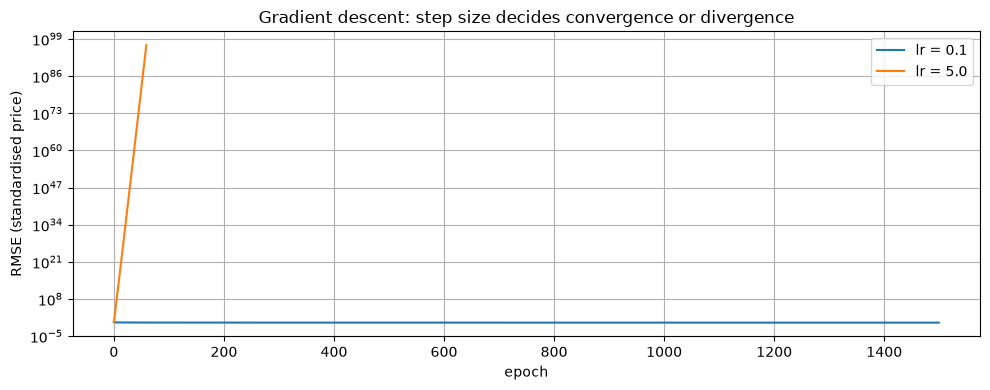

In [32]:
# And the same loop with a step size that is too large: it diverges instead of converging.
with np.errstate(over="ignore", invalid="ignore"):
    _, _, wild = gradient_descent(X, y_scaled, lr=5.0, epochs=60)

print("loss with lr=5.0, epoch 0 :", round(wild[0], 4))
print("loss with lr=5.0, epoch 59:", f"{wild[-1]:.3e}", "<- blew up")

fig, ax = plt.subplots()
ax.plot(trace, label="lr = 0.1")
ax.plot(wild, label="lr = 5.0")
ax.set_yscale("log")
ax.set_xlabel("epoch")
ax.set_ylabel("RMSE (standardised price)")
ax.set_title("Gradient descent: step size decides convergence or divergence")
ax.legend()
fig.tight_layout()

In [33]:
gd_val = (np.hstack([np.ones((X_val_t.shape[0], 1)), X_val_t]) @ np.concatenate([[b_gd], w_gd])) * y_std + y_mean
record("Gradient descent (1500 epochs)", y_val, gd_val, "iterative solver, same model as OLS")
print("it converges to (almost) the same place as the closed form - that is what should happen")
pd.DataFrame(results[-2:]).round(2)

it converges to (almost) the same place as the closed form - that is what should happen


,model,MAE,RMSE,R2,notes
0,Linear regression + log target,112592.81,256231.21,0.60,"log1p, no negative predictions"
1,Gradient descent (1500 epochs),125682.65,235174.78,0.67,"iterative solver, same model as OLS"


## 15. Linear, or polynomial?

Square feet per house has a curved relationship with price, so degree-2 interactions are worth one
measured attempt. The catch is column count: the transformed matrix has dozens of columns, and every
pair of them becomes a new feature. Penalisation is what makes that survivable.

In [34]:
# Small helper reused in this and the next sections: standardise the target before fitting,
# so an alpha means the same thing for every model below.
def scaled_target(estimator):
    return TransformedTargetRegressor(regressor=estimator, transformer=StandardScaler())

In [35]:
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train_t)
X_val_poly = poly.transform(X_val_t)
print("columns before expansion:", X_train_t.shape[1])
print("columns after  expansion:", X_train_poly.shape[1])

started = time.perf_counter()
poly_ols = LinearRegression().fit(X_train_poly, y_train)
print(f"plain least squares on {X_train_poly.shape[1]} columns took {time.perf_counter() - started:.1f}s")
record("Polynomial degree 2 (no penalty)", y_val, poly_ols.predict(X_val_poly), "all pairwise products")
pd.DataFrame(results[-1:]).round(2)

columns before expansion: 46
columns after  expansion: 1127


plain least squares on 1127 columns took 0.3s

,model,MAE,RMSE,R2,notes
0,Polynomial degree 2 (no penalty),141302.18,466667.24,-0.31,all pairwise products


In [36]:
poly_ridge = scaled_target(Pipeline([("scale", StandardScaler()), ("ridge", RidgeCV(alphas=np.logspace(1, 6, 12)))]))
poly_ridge.fit(X_train_poly, y_train)
record("Polynomial degree 2 + RidgeCV", y_val, poly_ridge.predict(X_val_poly), "penalised interactions")
print("alpha chosen by internal cross-validation:", f"{poly_ridge.regressor_.named_steps['ridge'].alpha_:,.0f}")
pd.DataFrame(results[-2:]).round(2)

alpha chosen by internal cross-validation: 658


,model,MAE,RMSE,R2,notes
0,Polynomial degree 2 (no penalty),141302.18,466667.24,-0.31,all pairwise products
1,Polynomial degree 2 + RidgeCV,116879.84,286381.83,0.51,penalised interactions


Read those two rows together with section 9: if the polynomial models are not clearly better than
plain linear after penalisation, the extra columns are not earning their keep, and the simpler model
wins on maintenance cost alone.

## 16. Do the combined features actually help?

The ratio features from section 6 were added on intuition. Intuition gets tested: fit the same model
with and without them and compare on the validation rows.

In [37]:
engineered = ["house_age", "was_renovated", "has_basement", "basement_ratio", "sqft_ratio_above", "lot_per_living"]
without_engineered = [c for c in numeric_features if c not in engineered]

def evaluate_columns(cols, label):
    pre = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), cols),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False), categorical_features),
    ])
    model = scaled_target(Pipeline([("pre", pre), ("ridge", Ridge(alpha=3.0))]))
    used = cols + categorical_features
    model.fit(train[used], train[TARGET])
    pred = model.predict(val[used])
    return {"features": label, "input columns": len(cols), "MAE": mean_absolute_error(y_val, pred), "R2": r2_score(y_val, pred)}

pd.DataFrame([evaluate_columns(without_engineered, "base columns only"), evaluate_columns(numeric_features, "base + engineered ratios")]).round(4)

,features,input columns,MAE,R2
0,base columns only,12,123266.4494,0.6676
1,base + engineered ratios,18,125186.7111,0.6670


## 17. Regularisation: Ridge, Lasso, ElasticNet

All three shrink coefficients; the difference is the shape of the penalty. The target is standardised
first, so one `alpha` value means the same thing across models.

In [38]:
specs = {
    "Ridge (alpha=10)": Ridge(alpha=10.0),
    "Lasso (alpha=0.001)": Lasso(alpha=1e-3, max_iter=20000),
    "ElasticNet (alpha=0.001, l1_ratio=0.5)": ElasticNet(alpha=1e-3, l1_ratio=0.5, max_iter=20000),
    "RidgeCV (cross-validated alpha)": RidgeCV(alphas=np.logspace(-2, 4, 30)),
}
for label, estimator in specs.items():
    model = scaled_target(estimator).fit(X_train_t, y_train)
    record(label, y_val, model.predict(X_val_t), "target standardised before fitting")

pd.DataFrame(results[-4:])[["model", "MAE", "RMSE", "R2"]].round(2)

,model,MAE,RMSE,R2
0,Ridge (alpha=10),124415.88,234759.47,0.67
1,Lasso (alpha=0.001),124703.71,234827.07,0.67
2,"ElasticNet (alpha=0.001, l1_ratio=0.5)",124717.43,234699.08,0.67
3,RidgeCV (cross-validated alpha),125359.26,234962.76,0.67


In [39]:
lasso = scaled_target(Lasso(alpha=1e-3, max_iter=20000)).fit(X_train_t, y_train)
coefs = lasso.regressor_.coef_
print(f"Lasso kept {int((coefs != 0).sum())} of {len(coefs)} coefficients and zeroed the rest")
print("raising alpha zeroes more of them: a simpler model for a small accuracy cost")

Lasso kept 39 of 46 coefficients and zeroed the rest
raising alpha zeroes more of them: a simpler model for a small accuracy cost


## 18. Cross-validation

One validation split gives one number, and that number is noisy. Five folds on the training rows give
a mean *and* a spread, which is what makes a comparison trustworthy.

In [40]:
from sklearn.model_selection import KFold, cross_val_score

cv_model = scaled_target(RidgeCV(alphas=np.logspace(-2, 4, 30)))
folds = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_mae = -cross_val_score(cv_model, X_train_t, y_train, cv=folds, scoring="neg_mean_absolute_error")
print("MAE per fold:", np.round(cv_mae, 0))
print(f"mean {cv_mae.mean():,.0f} +/- {cv_mae.std():,.0f}  <- the +/- is how much to trust a single split")

MAE per fold: [120349. 123403. 130851. 122292. 133744.]
mean 126,128 +/- 5,212  <- the +/- is how much to trust a single split


## 19. Tuning, and a tree model that needs no scaling

`RandomizedSearchCV` samples the interesting part of the space instead of testing every combination.
It searches on the **training rows only** with internal 3-fold CV, so the validation set stays clean
for the comparison that follows.

In [41]:
from scipy.stats import loguniform, randint

search_space = {
    "learning_rate": loguniform(0.02, 0.3),
    "max_iter": randint(150, 500),
    "max_leaf_nodes": randint(15, 63),
    "min_samples_leaf": randint(10, 60),
    "l2_regularization": loguniform(1e-3, 10.0),
}
hgb_search = RandomizedSearchCV(
    HistGradientBoostingRegressor(random_state=RANDOM_STATE),
    search_space,
    n_iter=12,
    cv=3,
    scoring="neg_mean_absolute_error",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
started = time.perf_counter()
hgb_search.fit(X_train_t, y_train)
print(f"searched 12 candidates x 3 folds in {time.perf_counter() - started:.1f}s")
best = {k: (int(v) if isinstance(v, (int, np.integer)) else round(float(v), 4)) for k, v in hgb_search.best_params_.items()}
print("best parameters:", best)
print(f"best cross-validated MAE: {-hgb_search.best_score_:,.0f}")

searched 12 candidates x 3 folds in 9.6s
best parameters: {'l2_regularization': 0.0216, 'learning_rate': 0.0294, 'max_iter': 280, 'max_leaf_nodes': 36, 'min_samples_leaf': 11}
best cross-validated MAE: 120,813


In [42]:
best_hgb = hgb_search.best_estimator_
record("HistGradientBoosting (tuned)", y_val, best_hgb.predict(X_val_t), "12-candidate random search")

forest = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE)
forest.fit(X_train_t, y_train)
record("Random forest (300 trees)", y_val, forest.predict(X_val_t), "mostly default settings")

pd.DataFrame(results[-2:])[["model", "MAE", "RMSE", "R2"]].round(2)

,model,MAE,RMSE,R2
0,HistGradientBoosting (tuned),111625.89,242270.01,0.65
1,Random forest (300 trees),115983.29,243283.08,0.64


## 20. The leaderboard

Every model measured so far, on the same validation rows. Sorted by MAE, because MAE is the number
that is easiest to explain to someone who is not a data scientist: "typically off by this many
dollars".

In [43]:
leaderboard = pd.DataFrame(results)[["model", "MAE", "RMSE", "R2", "notes"]].sort_values("MAE")
leaderboard["MAE"] = leaderboard["MAE"].round(0)
leaderboard["RMSE"] = leaderboard["RMSE"].round(0)
leaderboard["R2"] = leaderboard["R2"].round(3)
leaderboard = leaderboard.reset_index(drop=True)
leaderboard

,model,MAE,RMSE,R2,notes
0,HistGradientBoosting (tuned),111626.0,242270.0,0.646,12-candidate random search
1,Linear regression + log target,112593.0,256231.0,0.604,"log1p, no negative predictions"
2,Random forest (300 trees),115983.0,243283.0,0.643,mostly default settings
3,Polynomial degree 2 + RidgeCV,116880.0,286382.0,0.505,penalised interactions
4,Ridge (alpha=10),124416.0,234759.0,0.667,target standardised before fitting
5,Lasso (alpha=0.001),124704.0,234827.0,0.667,target standardised before fitting
6,"ElasticNet (alpha=0.001, l1_ratio=0.5)",124717.0,234699.0,0.668,target standardised before fitting
7,RidgeCV (cross-validated alpha),125359.0,234963.0,0.667,target standardised before fitting
8,Normal equation (closed form),125679.0,235075.0,0.667,solved by hand
9,Linear regression (scaled + one-hot),125679.0,235075.0,0.667,ordinary least squares


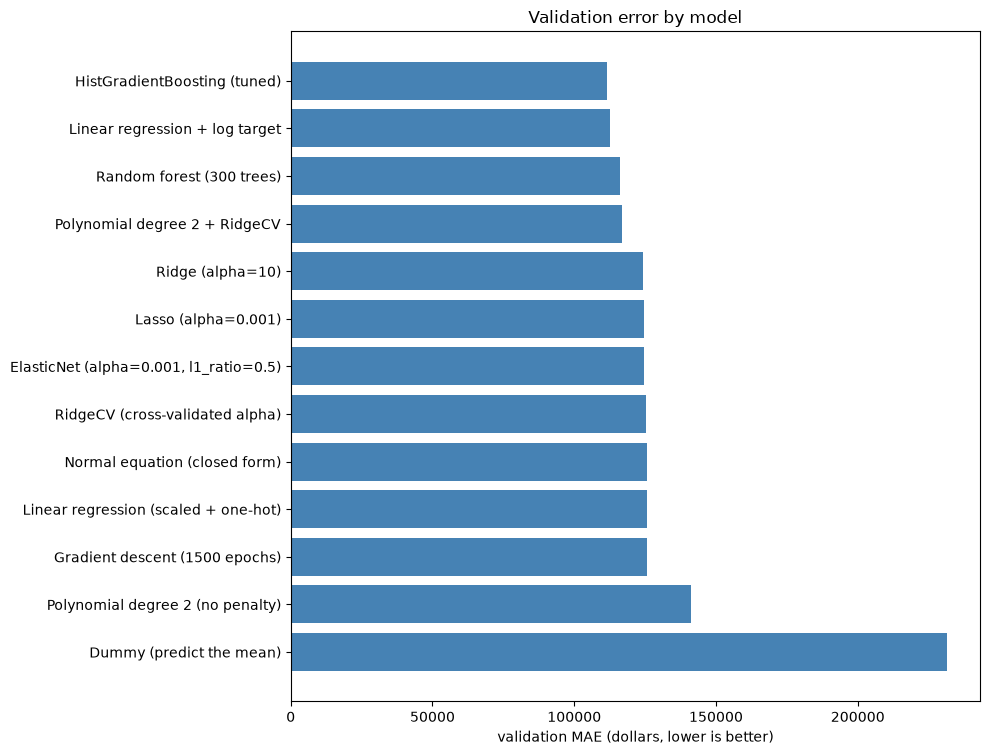

In [44]:
fig, ax = plt.subplots(figsize=(10, 0.45 * len(leaderboard) + 1.8))
ax.barh(leaderboard["model"], leaderboard["MAE"], color="steelblue")
ax.invert_yaxis()
ax.set_xlabel("validation MAE (dollars, lower is better)")
ax.set_title("Validation error by model")
ax.grid(False)
fig.tight_layout()

## 21. Where the best model is still wrong

A single error number hides structure. Residuals show whether the model is biased, and whether the
error grows with the price - the usual pattern in house prices, and not something tuning can fix.

In [45]:
best_val_pred = best_hgb.predict(X_val_t)
residuals = y_val - best_val_pred

print("leaderboard top three:")
print(leaderboard["model"].head(3).to_string(index=False))
print()
print("mean residual  :", round(float(residuals.mean()), 0))
print("median residual:", round(float(residuals.median()), 0))

leaderboard top three:
  HistGradientBoosting (tuned)
Linear regression + log target
     Random forest (300 trees)

mean residual  : 7939.0
median residual: -7011.0


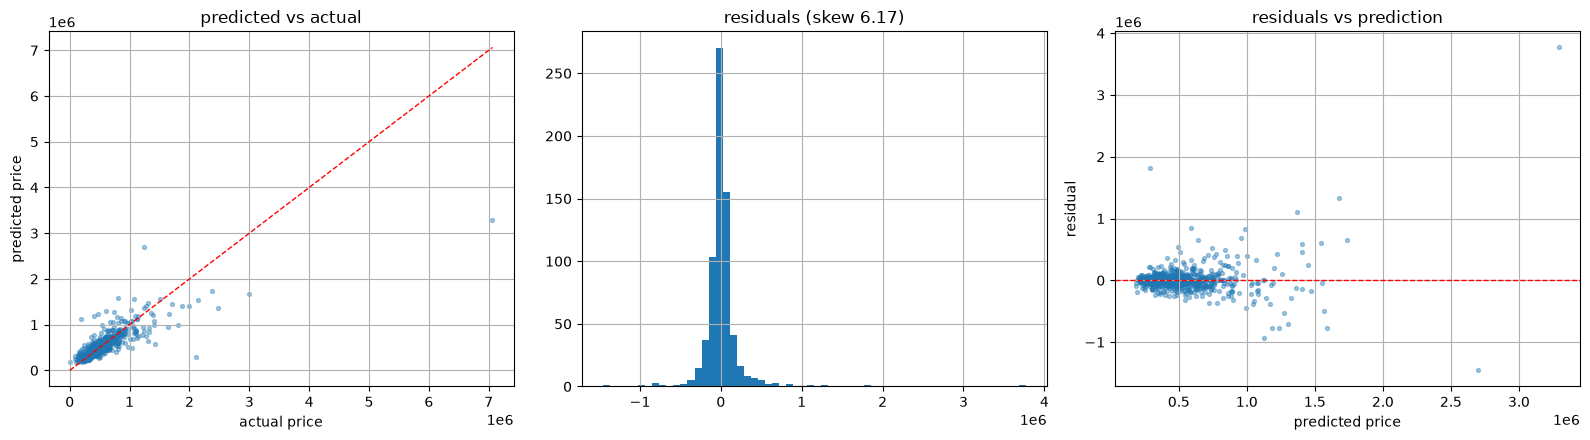

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].scatter(y_val, best_val_pred, s=8, alpha=0.4)
top = float(max(y_val.max(), best_val_pred.max()))
axes[0].plot([0, top], [0, top], "r--", linewidth=1)
axes[0].set_xlabel("actual price")
axes[0].set_ylabel("predicted price")
axes[0].set_title("predicted vs actual")

axes[1].hist(residuals, bins=60)
axes[1].set_title(f"residuals (skew {residuals.skew():.2f})")

axes[2].scatter(best_val_pred, residuals, s=8, alpha=0.4)
axes[2].axhline(0, color="r", linewidth=1, linestyle="--")
axes[2].set_xlabel("predicted price")
axes[2].set_ylabel("residual")
axes[2].set_title("residuals vs prediction")
fig.tight_layout()

In [47]:
bands = pd.qcut(y_val, 5, labels=["cheapest 20%", "20-40%", "40-60%", "60-80%", "dearest 20%"])
error_by_band = (
    pd.DataFrame({"band": bands.to_numpy(), "abs_error": np.abs(residuals.to_numpy())})
    .groupby("band", observed=True)["abs_error"]
    .agg(["count", "median", "mean"])
    .round(0)
)
error_by_band

,count,median,mean
band,,,
20-40%,133,49011.0,71369.0
40-60%,135,52882.0,71322.0
60-80%,137,69972.0,88851.0
cheapest 20%,141,36918.0,69098.0
dearest 20%,136,150132.0,258035.0


## 22. The test set, measured once

Everything up to here used `train` for fitting and `val` for deciding. The model is now refitted on
`train + val` and measured on `test` exactly once. That single number is the honest estimate of how
it behaves on houses it has never seen.

In [48]:
final_model = HistGradientBoostingRegressor(**hgb_search.best_params_, random_state=RANDOM_STATE)
final_model.fit(np.vstack([X_train_t, X_val_t]), np.concatenate([y_train, y_val]))
test_pred = final_model.predict(X_test_t)

final = {
    "MAE": mean_absolute_error(y_test, test_pred),
    "RMSE": rmse(y_test, test_pred),
    "R2": r2_score(y_test, test_pred),
    "median absolute error": float(np.median(np.abs(y_test - test_pred))),
    "rows": float(len(y_test)),
}
print("FINAL, measured once on the untouched test set")
for key, value in final.items():
    print(f"  {key:22s} {value:10,.3f}" if key == "R2" else f"  {key:22s} {value:10,.0f}")

FINAL, measured once on the untouched test set
  MAE                       109,094
  RMSE                      186,517
  R2                          0.731
  median absolute error      62,444
  rows                          682


In [49]:
print(f"validation MAE {leaderboard.iloc[0]['MAE']:,.0f} vs test MAE {final['MAE']:,.0f}")
print("close together -> the validation protocol was not fooling us")
print(f"a typical prediction is off by {final['MAE'] / y_test.median():.1%} of the median price")

validation MAE 111,626 vs test MAE 109,094
close together -> the validation protocol was not fooling us
a typical prediction is off by 23.0% of the median price


## 23. Save the results

Written next to this notebook so the numbers can be quoted in the report without re-running
anything.

In [50]:
results_csv = Path("house-price-manual-results.csv")
final_csv = Path("house-price-manual-final-test.csv")

pd.DataFrame(results).round(3).to_csv(results_csv, index=False)
pd.DataFrame([{"model": "HistGradientBoosting (tuned), refit on train+val", **final}]).to_csv(final_csv, index=False)

print("wrote", results_csv.resolve())
print("wrote", final_csv.resolve())

wrote C:\Users\novij\Desktop\Pba Softwareudvikling\2. Semester\LLMs for udviklere\project\LLM-group-a\exam_project\regression\house-price-manual-results.csv
wrote C:\Users\novij\Desktop\Pba Softwareudvikling\2. Semester\LLMs for udviklere\project\LLM-group-a\exam_project\regression\house-price-manual-final-test.csv


## 24. What this exercise showed

**What actually mattered, in order of size of effect**

1. Three impossible prices. A 1 180 sqft house listed at 26.6 M - 22 534 per square foot against a
   median of 245 - plus two smaller data-entry errors. That one row made RMSE read as a million
   dollars and R2 read as 0.03 for *every* model, however good. Dropping 3 rows out of 4 546 took
   plain linear regression from R2 0.03 to R2 0.67. Nothing else in this notebook comes close.
2. Refusing impossible rows (price <= 0, zero bedrooms, zero bathrooms) and exact duplicates before
   fitting anything.
3. The choice of model mattered surprisingly little. Everything from plain least squares
   (MAE 125 679) to the tuned gradient booster (MAE 111 626) fits inside an 11% band, and both
   linear models actually score a *higher* R2 than the booster does.
4. The log target did the most of any modelling choice: MAE 125 679 -> 112 593, and it removed the
   one negative price prediction that plain least squares produced. It costs R2 (0.667 -> 0.604),
   because a log loss cares about relative error and stops chasing the few very expensive houses.
5. Regularisation (Ridge, Lasso, ElasticNet, RidgeCV) changed almost nothing: 124 416 to 125 359.
   This data is not ill-conditioned enough to need it. What it bought was *trust* - a cross-validated
   mean with a spread - rather than accuracy.
6. The booster wins on MAE while losing on RMSE and R2 at the same time: it is better on a typical
   house and worse on the very expensive ones. That matches the residual table above, where median
   error in the dearest fifth (150 132) is four times the cheapest fifth (36 918). Which metric
   matters is a decision for whoever uses the model, not for the leaderboard.

**What did not pay off, kept here so nobody repeats it**

- The engineered ratio features. Measured directly in section 16: validation MAE got slightly *worse*
  with them (123 266 -> 125 187). Negative result, left in the notebook on purpose.
- Degree-2 polynomial expansion. Unpenalised it scores R2 -0.314, because it overfits wildly;
  penalised it reaches MAE 116 880 but R2 drops to 0.505, on a matrix 25 times wider.
- Classification metrics (accuracy, confusion matrix) on a continuous target - a real `ValueError`.
- Trimming outliers by IQR - it removes exactly the expensive houses that matter.
- `price_per_sqft` as a feature - it contains the answer. The ~1.0 R2 is proof of leakage, not skill.

**Honest limitations**

- 4 600 sales from one county (King County, WA) over a few months of 2014. It will not transfer to
  another market or another year.
- The data has no school district, commute time, crime rate or interior condition - the things a
  human appraiser would reach for first.
- A single 15% test split (~690 rows) has real variance; the validation-versus-test gap printed
  above quantifies it for this run only.